# Toroidal Manifolds

In [ ]:
import numpy as np
import matplotlib.pyplot as plt 
from scipy.integrate import odeint

%matplotlib inline
%config InlineBackend.figure_format='retina'
plt.rcParams.update({
    "text.usetex": True,
})

## Higher Dimensional Torus

From *Mem-elements for Neuromorphic Circuits with Artificial Intelligence Applications*

"Higher dimensional torus and large expanded chaotic attractor"

$\frac{dx}{dt} = y$

$\frac{dy}{dt} = z$

$\frac{dz}{dt} = -\alpha y z - (\omega_0^2 + 3\beta x^2)y + A sin (\omega t)$

$\alpha = 0.5, \beta = 0.4975, A = 0.5, \omega_0^2 = 0.5896, \omega = 0.14$

The systems below vary these parameters and the nonlinearities.

[-1.02909432, -1.70628519, -0.18950172]


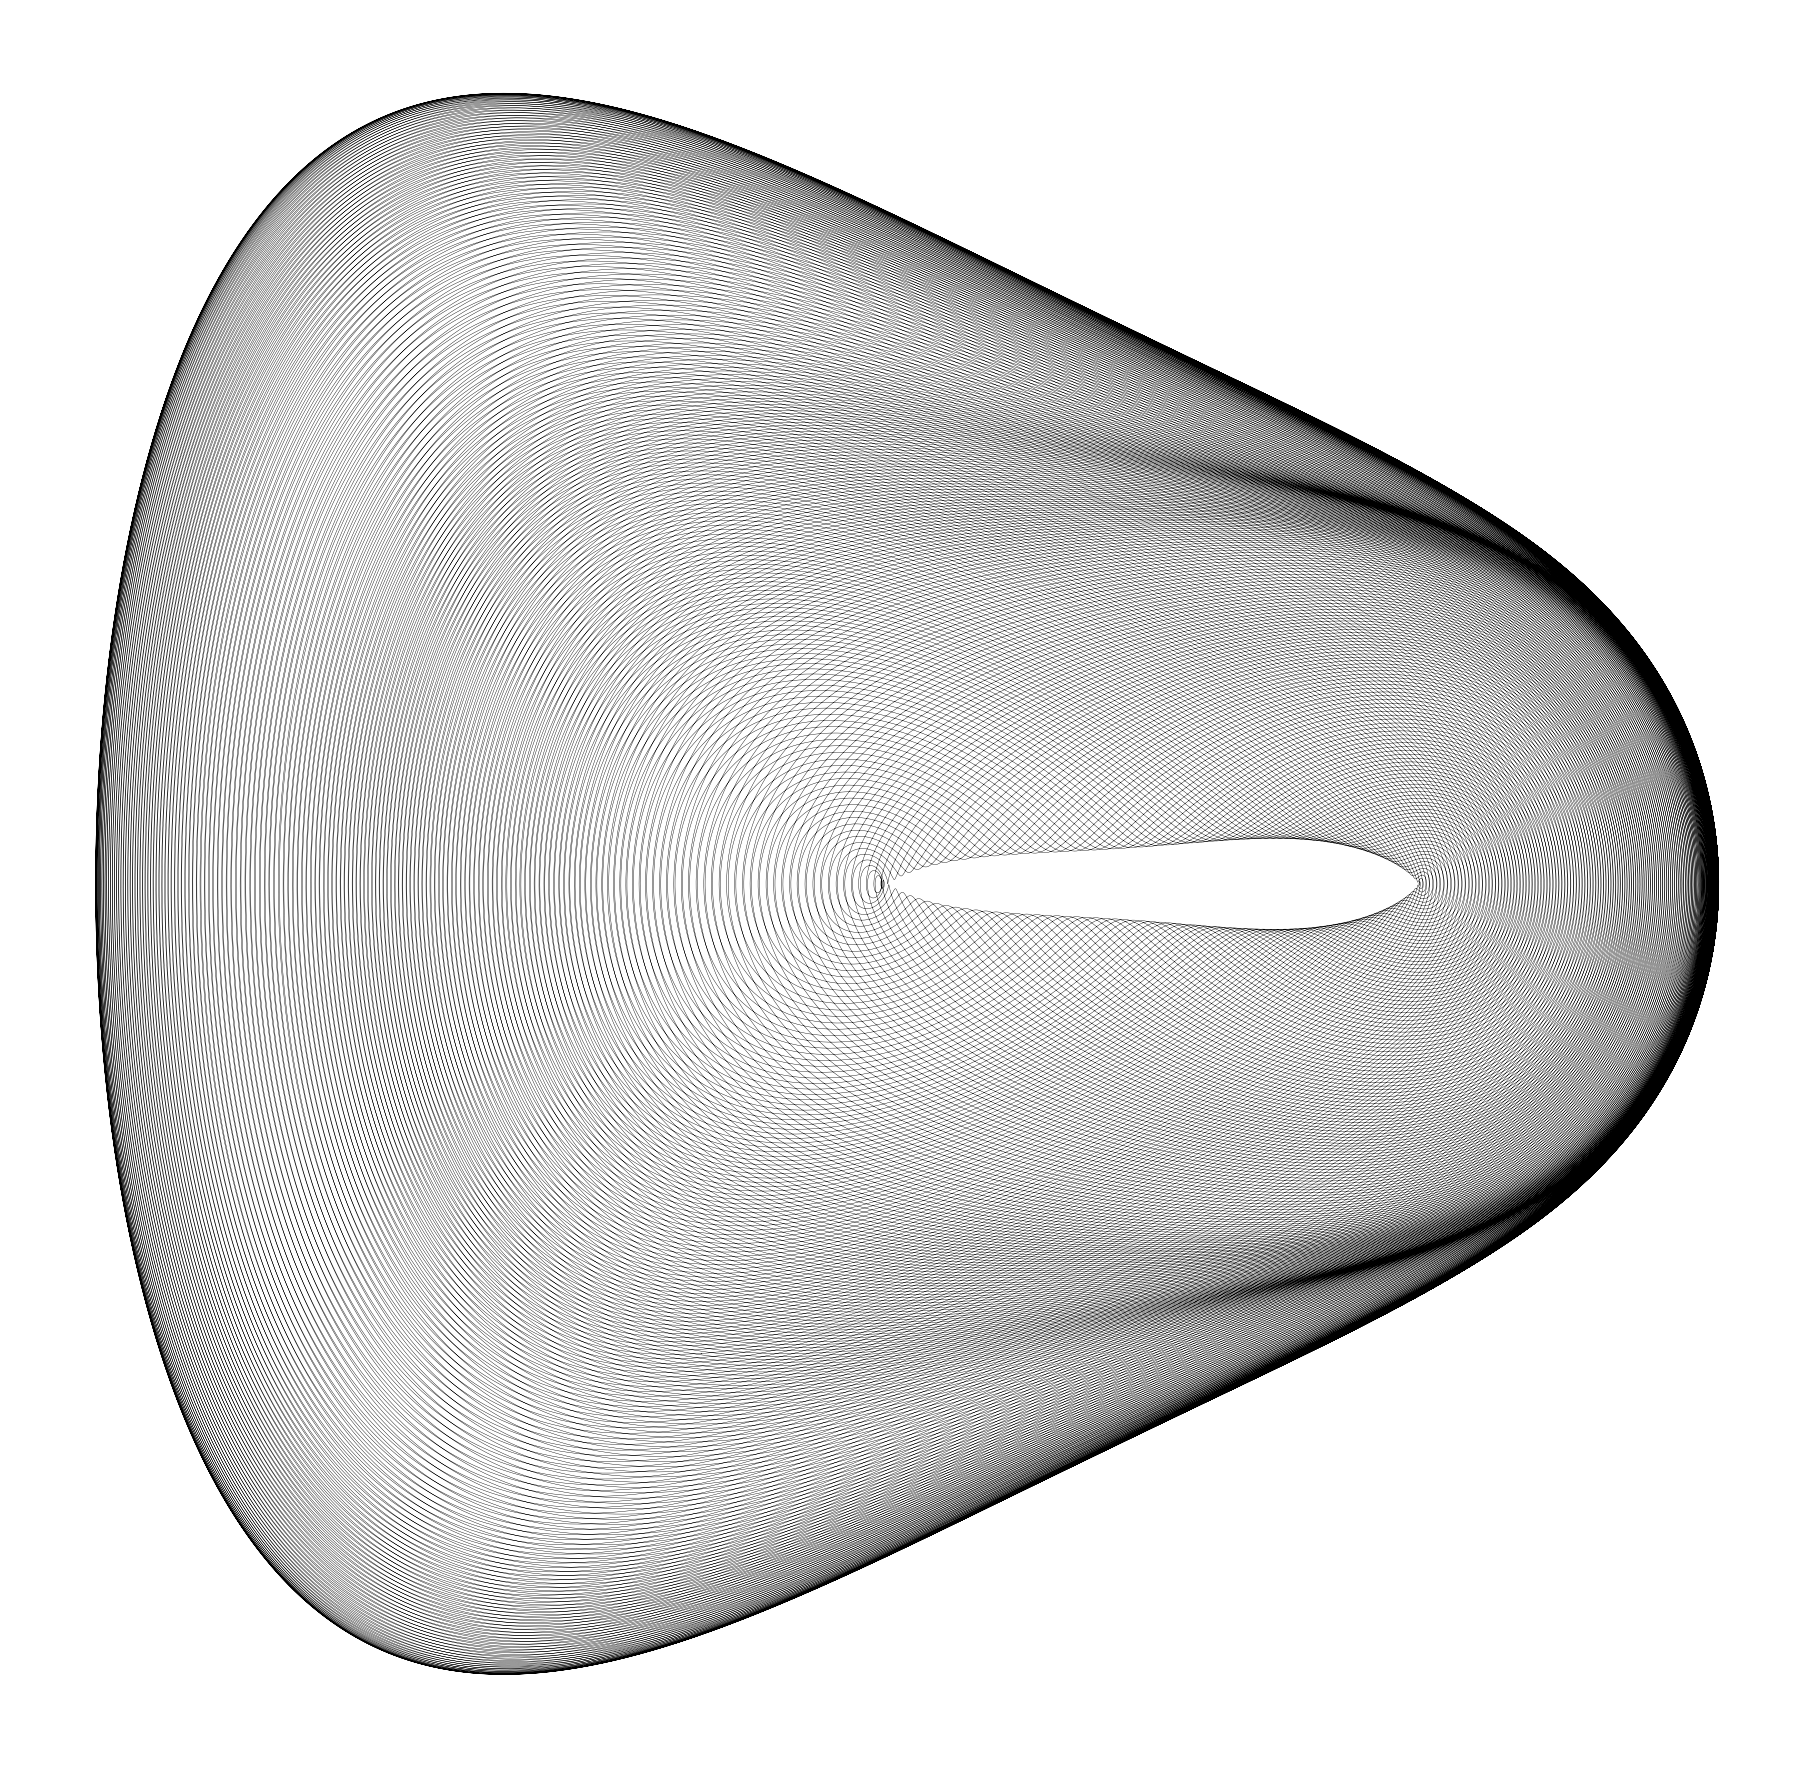

In [8]:
def hd_torus(u, t, alpha=0.6, beta=0.5975, A=0.6, omega_0_2=0.5896, omega=0.94):
    x, y, z = u
    dxdt = y
    dydt = z
    dzdt = -alpha*y*z - (omega_0_2 + 3*beta*x**2)*y + A*np.sin(omega*t)
    return [dxdt, dydt, dzdt]

t_0 = 0
dt = .001
t_final = 2299.38
t = np.arange(t_0, t_final, dt)
u0 = np.random.randn(3)
u0 = [-1.02909432, -1.70628519, -0.18950172]

print(u0)
sol = odeint(hd_torus, u0, t)
fig = plt.figure(figsize=(16,16))
plt.axis('off')
plt.plot(*sol.T[:2], lw=.2, c='k')
plt.show()

### Saturated Variant

$\alpha = 0.00056, \beta = 0.000095375, A = 0.00104, \omega_0^2 = 0.000996, \omega = 0.00069$

$\frac{dx}{dt} = \sinh^{-1}(\tanh(y^3))$

$\frac{dy}{dt} = \sin^{-1}(\tanh(9z))$

$\frac{dz}{dt} = -\alpha y z - (\omega_0^2 + 3\beta x^2)y + A sin (\omega t)$

[-1.02909432, -1.70628519, -0.18950172]


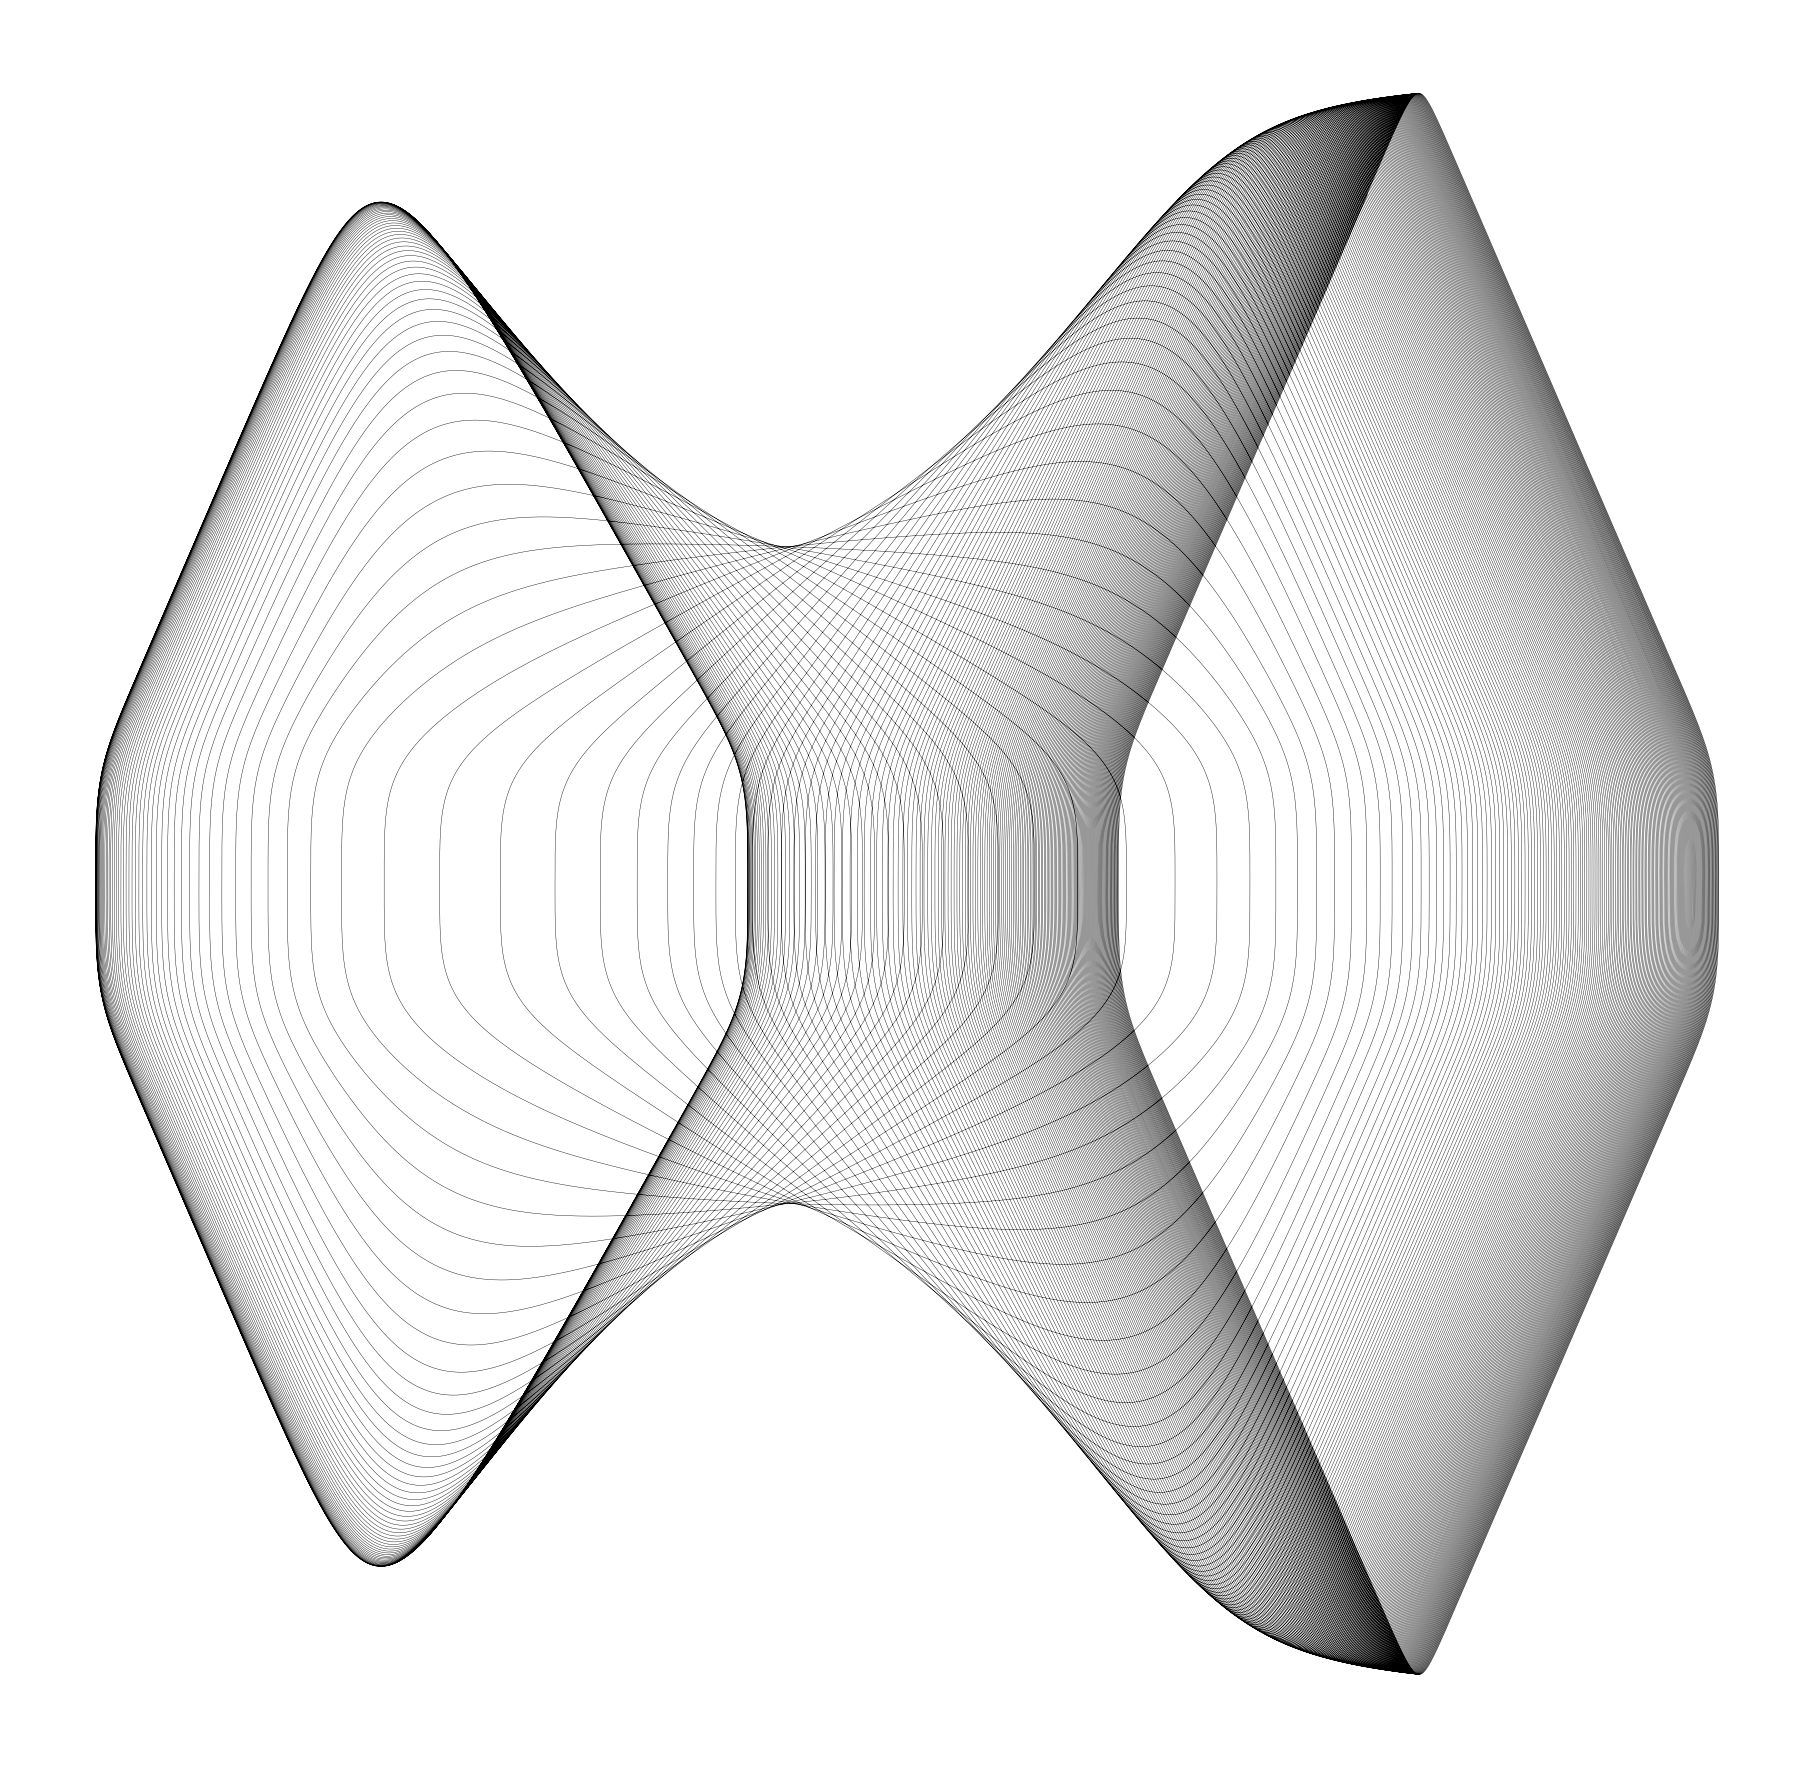

In [126]:
def hd_torus(u, t, alpha=0.00056, beta=0.000095375, A=0.00104, omega_0_2=.000996, omega=0.00069):
    x, y, z = u
    dxdt = np.arcsinh(np.tanh(y**3))
    dydt = np.arcsin(np.tanh(z*9))
    dzdt = -alpha*y*z - (omega_0_2 + 3*beta*x**2)*y + A*np.sin(omega*t)
    return [dxdt, dydt, dzdt]

t_0 = 0
dt = .001
t_final = 3200
t = np.arange(t_0, t_final, dt)
u0 = np.random.randn(3)
u0 = [-1.02909432, -1.70628519, -0.18950172]

print(u0)
sol = odeint(hd_torus, u0, t)
fig = plt.figure(figsize=(16,16))
plt.axis('off')
plt.plot(*sol.T[:2], lw=.2, c='k')
plt.show()

### Rounded Variant

$\alpha = 0.3, \beta = 0.45, A = 0.1, \omega_0^2 = 0.9, \omega = 0.45$

$\frac{dx}{dt} = \alpha\tanh(y^4)$

$\frac{dy}{dt} = \beta\tanh(\mathrm{round}((222z)^3))$

$\frac{dz}{dt} = -\alpha y z - (\omega_0^2 + 3\beta x^2)y + \tanh(A sin (\omega t))$

In [ ]:
def hd_torus(u, t, alpha=0.3, beta=0.45, A=.1, omega_0_2=.9, omega=.45):
    x, y, z = u
    dxdt = alpha*np.tanh(y**4)
    dydt = beta*np.tanh(np.round((222*z)**3))
    dzdt = -alpha*y*z - (omega_0_2 + 3*beta*x**2)*y + np.tanh(A*np.sin(omega*t))
    return [dxdt, dydt, dzdt]

t_0 = 0
dt = .001
t_final = 1109
t = np.arange(t_0, t_final, dt)
u0 = [1.228980379087397,0.2454942747854434,0.03621814661143543]

print('['+','.join([str(x) for x in u0])+']')
sol = odeint(hd_torus, u0, t)
lt = .1*np.random.randn(3,3)
print(lt)
sol = np.tanh(((lt@sol.T).T))
fig = plt.figure(figsize=(16,16))
plt.axis('off')
plt.plot(sol.T[0], sol.T[1], lw=.1, c='k')
plt.show()
#[1.228980379087397,0.2454942747854434,0.03621814661143543]
#[[ 0.09375038 -0.03828068  0.09298375]
 #[ 0.18768197 -0.01786983  0.14441695]
 #[ 0.00688916  0.00068446  0.0744744 ]]

0.6755133451815785,-0.028873140937599674,0.9629120359769516


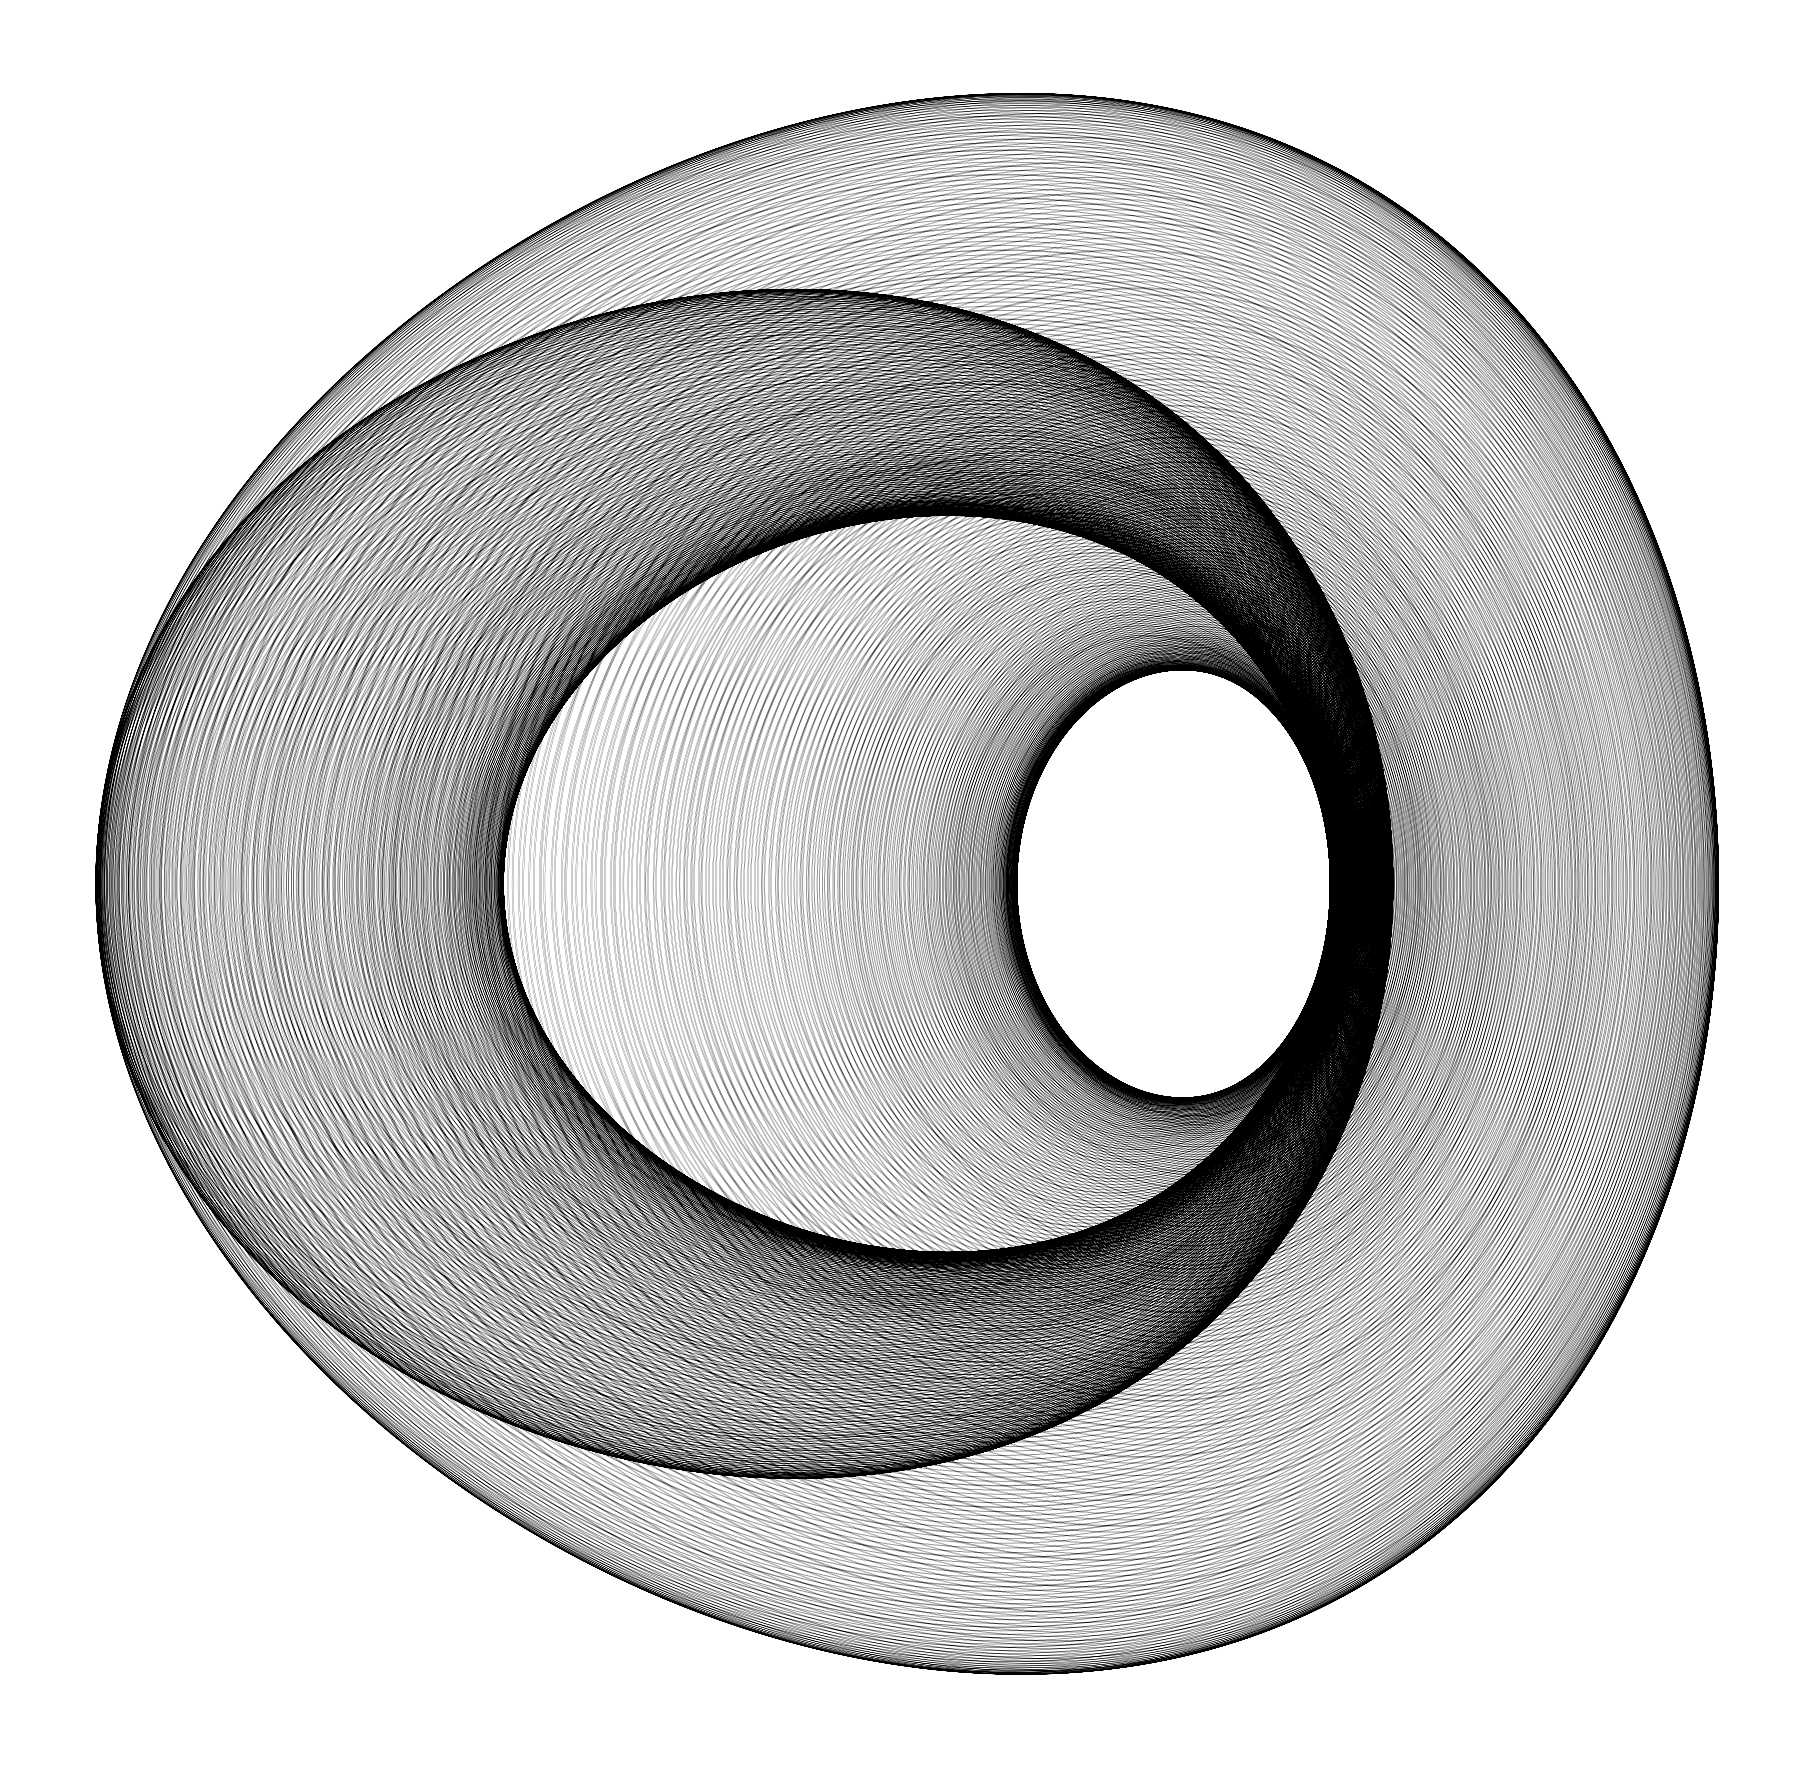

In [472]:
t_0 = 0
dt = .001
t_final = 4526.1
t = np.arange(t_0, t_final, dt)
u0 = [0.6755133451815785,-0.028873140937599674,0.9629120359769516]
print(*u0, sep=',')
sol = odeint(hd_torus, u0, t)
fig = plt.figure(figsize=(16,16))
plt.axis('off')
plt.plot(sol.T[0], sol.T[1], lw=.1, c='k')
plt.show()